In [1]:
import pandas as pd

# Load the original PhiUSIIL dataset (uploaded CSV file)
df = pd.read_csv('/content/PhiUSIIL_Phishing_URL_Dataset.csv')

print('Shape (rows, columns):', df.shape)
print('Missing labels:', df['label'].isna().sum())


Shape (rows, columns): (235795, 56)
Missing labels: 0


In [2]:
#Count how many columns are numeric and how many are text
print(df.dtypes.value_counts())

# Show only the columns that have missing values
missing = df.isna().sum()
print('\nColumns with missing values:')
print(missing[missing > 0])

int64      41
float64    10
object      5
Name: count, dtype: int64

Columns with missing values:
Series([], dtype: int64)


In [3]:
# Count repeated URLs
print('Duplicate URLs:', df['URL'].duplicated().sum())

# Count repeated rows using only the numeric feature columns (label excluded)
feature_cols = df.select_dtypes(include='number').columns.drop('label')
print('Duplicate feature rows:', df.duplicated(subset=feature_cols).sum())

Duplicate URLs: 425
Duplicate feature rows: 808


In [4]:
# Remove repeated URLs (keep the first row of each URl)
before = len(df)
df = df.drop_duplicates(subset='URL').reset_index(drop=True)

print('Rows before:', before)
print('Rows after:', len(df))
print('Rows removed:', before - len(df))

Rows before: 235795
Rows after: 235370
Rows removed: 425


In [5]:
# Count repeated features rows again, after removing duplicate URLs
feature_cols = df.select_dtypes(include='number').columns.drop('label')
print('Duplicate feature rows now:', df.duplicated(subset=feature_cols).sum())

Duplicate feature rows now: 808


In [6]:
# Group rows that have identical features, then count distinct labels in each group
grouped = df.groupby(list(feature_cols))['label'].nunique()

# Group with more than 1 label are conflicting groups
print('Groups with conflicting labels:', (grouped > 1).sum())

Groups with conflicting labels: 0


In [7]:
# Remove rows with identical features (keep the first one)
before = len(df)
df = df.drop_duplicates(subset=feature_cols).reset_index(drop=True)

print('Rows before:', before)
print('Rows after:', len(df))
print('Rows removed:', before - len(df))

Rows before: 235370
Rows after: 234562
Rows removed: 808


In [ ]:
# Count and percentage of each class (0 = phishing,, 1 = legitimate)
counts = df['label'].value_counts()
print(counts)
print((counts / len(df) * 100).round(2))

label
1    134850
0     99712
Name: count, dtype: int64
label
1    57.49
0    42.51
Name: count, dtype: float64


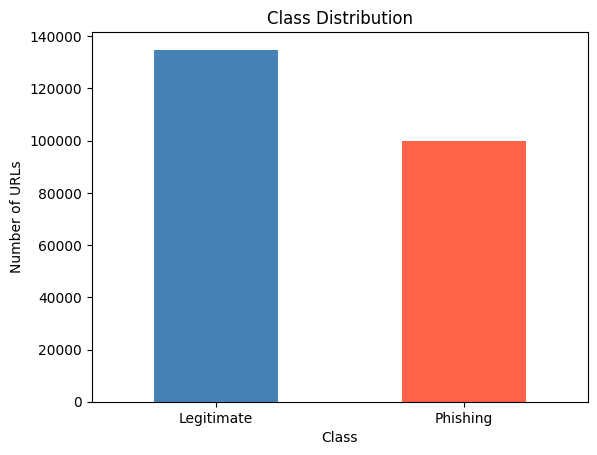

In [ ]:
import matplotlib.pyplot as plt

# Rename labels so the chart is easy to read
names = df['label'].map({0: 'Phishing', 1: 'Legitimate'}).value_counts()

# Draw a bar chart of class counts
names.plot(kind='bar', color=['steelblue', 'tomato'])
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of URLs')
plt.xticks(rotation=0)
plt.show()

Legitimate URLs are 57.49%. Phishing URLs are 42.51%. The classes are close, so the data is roughly balanced. Still, we will not rely on accuracy alone. We will also use Recall, F1, and PR-AUC.

In [ ]:
# Get the 50 numeric feature columns (label excluded)
num_cols = df.select_dtypes(include='number').columns.drop('label')

# Count unique values in each column
unique_counts = df[num_cols].nunique()

# Split into binary (2 unique values) and others
binary_cols = unique_counts[unique_counts == 2].index.tolist()
other_cols = unique_counts[unique_counts > 2].index.tolist()

print('Total numeric features:', len(num_cols))
print('Binary feature:', len(binary_cols))
print('Other feature:', len(other_cols))

Total numeric features: 50
Binary feature: 19
Other feature: 31


In [ ]:
# Print the names of binary and other features
print('Binary features:')
print(binary_cols)
print('\nOther features:')
print(other_cols)


Binary features:
['IsDomainIP', 'HasObfuscation', 'IsHTTPS', 'HasTitle', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo']

Other features:
['URLLength', 'DomainLength', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'LineOfCode', 'LargestLineLength', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'NoOfPopup', 'NoOfiFrame', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [ ]:
print(df['NoOfURLRedirect'].value_counts())
print(df['NoOfSelfRedirect'].value_counts())

NoOfURLRedirect
0    203175
1     31387
Name: count, dtype: int64
NoOfSelfRedirect
0    225118
1      9444
Name: count, dtype: int64


In [ ]:
# Share of rows where each binary features equals 1, for each class
share = df.groupby('label')[binary_cols].mean().T * 100

# Rename columns for readability (0 = phishing, 1 = legitimate)
share.columns = ['Phishing (%)', 'Legitimate (%)']

# Show thw table rounded to 1 decimal
print(share.round(1))

                       Phishing (%)  Legitimate (%)
IsDomainIP                      0.6             0.0
HasObfuscation                  0.5             0.0
IsHTTPS                        48.8           100.0
HasTitle                       67.6            99.9
HasFavicon                      8.8            56.7
Robots                          6.6            41.7
IsResponsive                   31.3            85.4
NoOfURLRedirect                15.3            12.0
NoOfSelfRedirect                5.8             2.7
HasDescription                  4.4            73.7
HasExternalFormSubmit           0.4             7.4
HasSocialNet                    0.5            79.5
HasSubmitButton                 8.5            66.1
HasHiddenFields                 9.4            59.1
HasPasswordField                5.4            13.8
Bank                            5.4            18.2
Pay                             6.0            36.9
Crypto                          0.6             3.7
HasCopyright

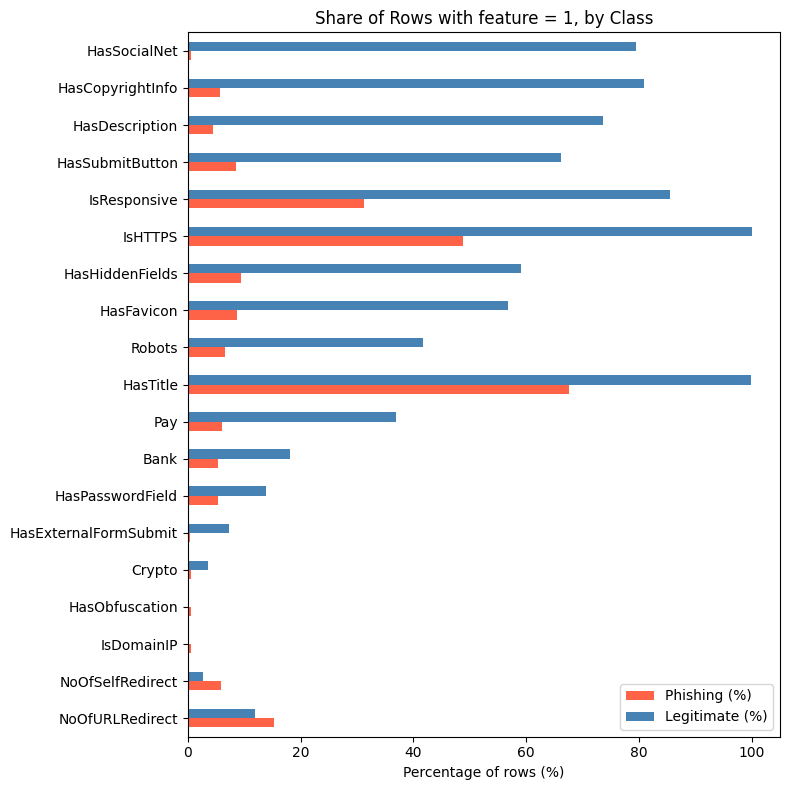

In [ ]:
import matplotlib.pyplot as plt

# Sort features by the difference between the two classes
share['Difference'] = share['Legitimate (%)'] - share['Phishing (%)']
sorted_share = share.sort_values('Difference')

# Draw a horizontal bar chart for both classes
sorted_share[['Phishing (%)', 'Legitimate (%)']].plot(
    kind='barh', figsize=(8, 8), color=['tomato', 'steelblue'])
plt.title('Share of Rows with feature = 1, by Class')
plt.xlabel('Percentage of rows (%)')
plt.tight_layout()
plt.show()

Some binary features differ a lot between the two classes. HasSocialNet, HasCopyrightInfo and HasDescription are much more common in legitimate URLs than in phishing URLs. IsHTTPS and HasTitle are common in both classes, so they separate the classes less. This is only a first look. Feature importance from the models will show the final picture.

In [ ]:
# Median of each continuous feature for each class
median_table = df.groupby('label')[other_cols].median().T

# Rename columns (0 = phishing, 1 = legitimate)
median_table.columns = ['Phishing (median)', 'Legitimate (median)']

# Show the table rounded to 2 decimals
print(median_table.round(2))

                            Phishing (median)  Legitimate (median)
URLLength                               34.00                26.00
DomainLength                            22.00                19.00
URLSimilarityIndex                      51.63               100.00
CharContinuationRate                     0.73                 1.00
TLDLegitimateProb                        0.02                 0.52
URLCharProb                              0.05                 0.06
TLDLength                                3.00                 3.00
NoOfSubDomain                            1.00                 1.00
NoOfObfuscatedChar                       0.00                 0.00
ObfuscationRatio                         0.00                 0.00
NoOfLettersInURL                        19.00                13.00
LetterRatioInURL                         0.58                 0.48
NoOfDegitsInURL                          0.00                 0.00
DegitRatioInURL                          0.00                 

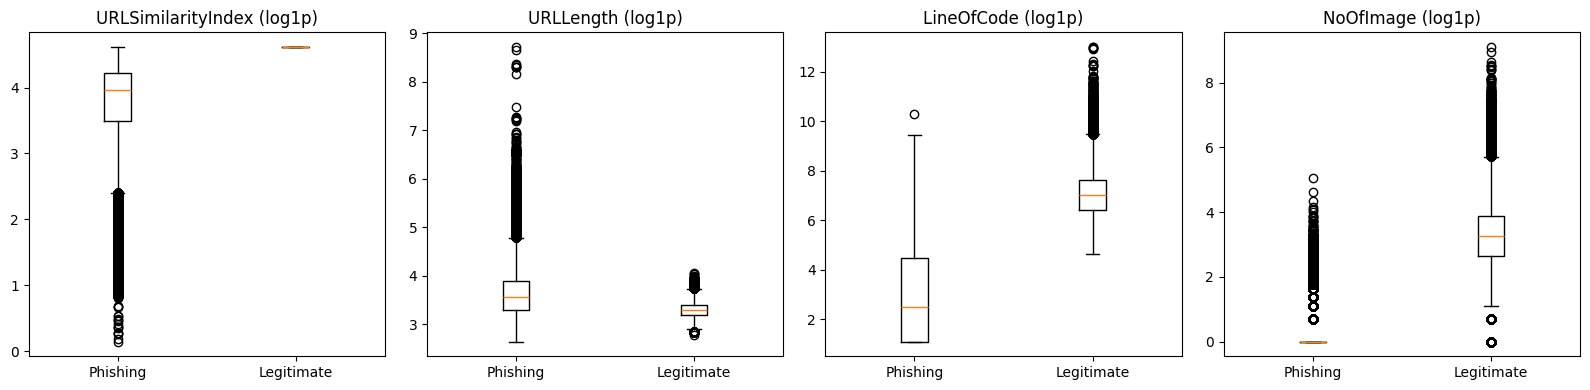

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Four features to plot: similarity, URL-based, page-based (x2)
feats = ['URLSimilarityIndex', 'URLLength', 'LineOfCode', 'NoOfImage']

# Draw one boxplot per feature, split by class (log scale for skewed values)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, f in zip(axes, feats):
    data = [np.log1p(df.loc[df['label'] == 0, f]),
            np.log1p(df.loc[df['label'] == 1, f])]
    ax.boxplot(data, tick_labels=['Phishing', 'Legitimate'])
    ax.set_title(f + ' (log1p)')
plt.tight_layout()
plt.show()

The boxplots compare four features for phishing and legitimate URLs. URLSimilarityIndex shows the biggest difference between the two classes. This matches the median table, where the values are 51.63 for phishing and 100.00 for legitimate. This is only a first look. We will test the effect of this feature later with an ablation study.

In [ ]:
# Correlation of each numeric feature with the label
corr_with_label = df[list(num_cols) + ['label']].corr()['label'].drop('label')

# Sort by strength (absolute value), keep the top 10
top10 = corr_with_label.abs().sort_values(ascending=False).head(10)

# Show the original signed values for these 10 features
print(corr_with_label[top10.index].round(3))

URLSimilarityIndex       0.860
HasSocialNet             0.783
HasCopyrightInfo         0.742
HasDescription           0.689
IsHTTPS                  0.614
DomainTitleMatchScore    0.583
HasSubmitButton          0.578
IsResponsive             0.553
URLTitleMatchScore       0.537
SpacialCharRatioInURL   -0.533
Name: label, dtype: float64


We calculated the correlation of each numeric feature with the label. URLSimilarityIndex has the strongest correlation (0.860). HasSocialNet, HasCopyrightInfo and HasDescription are also high. SpacialCharRatioInURL is the only negative feature in the top 10. Correlation shows only a linear link, so we will check feature importance and ablation later.

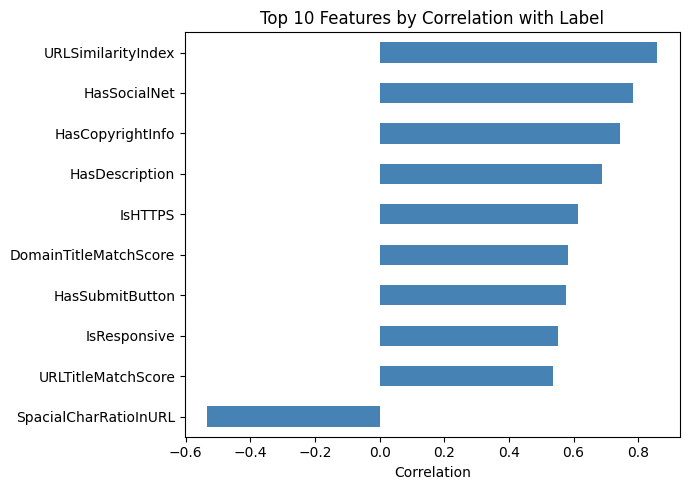

In [ ]:
import matplotlib.pyplot as plt

# Bar chart of the top 10 correlations with the label
corr_with_label[top10.index].sort_values().plot(kind='barh', figsize=(7, 5), color='steelblue')
plt.title('Top 10 Features by Correlation with Label')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Correlation between all 50 features (label not included)
corr_matrix = df[num_cols].corr().abs()

# Keep only the upper triangle so each pair appears once
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Turn the table into a list of pairs, drop empty values
pairs = upper.stack().reset_index()
pairs.columns = ['Feature A', 'Feature B', 'Correlation']

# Keep pairs above 0.9 and sort from highest to lowest
high_pairs = pairs[pairs['Correlation'] > 0.9].sort_values('Correlation', ascending=False)

print('Number of pairs above 0.9:', len(high_pairs))
print(high_pairs.round(3).to_string(index=False))

Number of pairs above 0.9: 2
            Feature A          Feature B  Correlation
DomainTitleMatchScore URLTitleMatchScore        0.961
            URLLength   NoOfLettersInURL        0.956


Only two feature pairs have a correlation above 0.9: DomainTitleMatchScore with URLTitleMatchScore, and URLLength with NoOfLettersInURL. Each pair measures a similar thing. URLSimilarityIndex is not in any of these pairs, so no other feature copies it at this threshold.

In [ ]:
from sklearn.model_selection import train_test_split

# X = 50 numeric features, y = label (0 = phishing, 1 = legitimate)
X = df[num_cols]
y = df['label']

# Stratified 70/30 split with a fixed random seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

print('Train shape:', X_train.shape)
print('Test shape :', X_test.shape)
print('Train legitimate %:', round(y_train.mean() * 100, 2))
print('Test legitimate %:', round(y_test.mean() * 100, 2))

Train shape: (164193, 50)
Test shape : (70369, 50)
Train legitimate %: 57.49
Test legitimate %: 57.49


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

# Baseline model: always predicts the most frequent class
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)

# Metrics for the phishing class (pos_label=0)
print('Accuracy :', round(accuracy_score(y_test, pred), 4))
print('Precision:', precision_score(y_test, pred, pos_label=0, zero_division=0))
print('Recall   :', recall_score(y_test, pred, pos_label=0, zero_division=0))
print('F1       :', f1_score(y_test, pred, pos_label=0, zero_division=0))
print('Confusion matrix (rows = true, cols = predicted; order: 0, 1):')
print(confusion_matrix(y_test, pred, labels=[0, 1]))

Accuracy : 0.5749
Precision: 0.0
Recall   : 0.0
F1       : 0.0
Confusion matrix (rows = true, cols = predicted; order: 0, 1):
[[    0 29914]
 [    0 40455]]


In [ ]:
from sklearn.preprocessing import StandardScaler

# Fit the scaler on training data only
scaler = StandardScaler()
scaler.fit(X_train)

# Apply the same scaler to both train and test
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Scaled train shape:', X_train_scaled.shape)
print('Scaled test shape :', X_test_scaled.shape)
print('Train mean (first 3 features):', X_train_scaled.mean(axis=0)[:3].round(3))
print('Train std  (first 3 features):', X_train_scaled.std(axis=0)[:3].round(3))


Scaled train shape: (164193, 50)
Scaled test shape : (70369, 50)
Train mean (first 3 features): [-0. -0. -0.]
Train std  (first 3 features): [1. 1. 1.]


In [ ]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score,
                             confusion_matrix)

def evaluate(model, X_te, y_te, name):
    """Return key metrics for the phishing class (label 0)."""
    pred = model.predict(X_te)
    # Probability of the phishing class (column 0)
    phish_score = model.predict_proba(X_te)[:, 0]
    # For ROC-AUC and PR-AUC, phishing is treated as the positive class
    y_phish = (y_te == 0).astype(int)
    return {
        'Model': name,
        'Precision': precision_score(y_te, pred, pos_label=0),
        'Recall': recall_score(y_te, pred, pos_label=0),
        'F1': f1_score(y_te, pred, pos_label=0),
        'PR-AUC': average_precision_score(y_phish, phish_score),
        'ROC-AUC': roc_auc_score(y_phish, phish_score),
        'Confusion': confusion_matrix(y_te, pred, labels=[0, 1]).tolist()
    }

print('Helper function ready')

Helper function ready


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score
import pandas as pd

# Scorer: F1 for the phishing class (label 0)
f1_phish = make_scorer(f1_score, pos_label=0)

# Pipeline: scaling + Logistic Regression
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

# Hyperparameter grid for C
lr_grid = {'model__C': [0.01, 0.1, 1, 10]}

# 3-fold cross-validation on the training data only
lr_search = GridSearchCV(lr_pipe, lr_grid, scoring=f1_phish, cv=3, n_jobs=-1)
lr_search.fit(X_train, y_train)

print('Best C:', lr_search.best_params_)
print('Best CV F1 (phishing):', round(lr_search.best_score_, 4))

# Evaluate the best model once on the test set
lr_result = evaluate(lr_search.best_estimator_, X_test, y_test, 'Logistic Regression')
print(pd.Series(lr_result))

Best C: {'model__C': 10}
Best CV F1 (phishing): 0.9998
Model             Logistic Regression
Precision                         1.0
Recall                       0.999699
F1                            0.99985
PR-AUC                            1.0
ROC-AUC                           1.0
Confusion    [[29905, 9], [0, 40455]]
dtype: object


In [ ]:
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

# Dictionary to collect results of all models (key = model name)
results = {'Logistic Regression': lr_result}

# Hyperparameter grid
dt_grid = {'max_depth': [3, 5, 10, None],
           'min_samples_leaf': [1, 5, 20]}

# 3-fold CV on training data only (trees do not need scaling)
dt_search = GridSearchCV(DecisionTreeClassifier(random_state=42),
                         dt_grid, scoring=f1_phish, cv=3, n_jobs=-1)
dt_search.fit(X_train, y_train)

print('Best params:', dt_search.best_params_)
print('Best CV F1 (phishing):', round(dt_search.best_score_, 4))

# Evaluate the best model once on the test set
dt_result = evaluate(dt_search.best_estimator_, X_test, y_test, 'Decision Tree')
results['Decision Tree'] = dt_result
print(pd.Series(dt_result))

Best params: {'max_depth': 3, 'min_samples_leaf': 1}
Best CV F1 (phishing): 1.0
Model                   Decision Tree
Precision                         1.0
Recall                       0.999933
F1                           0.999967
PR-AUC                       0.999962
ROC-AUC                      0.999967
Confusion    [[29912, 2], [0, 40455]]
dtype: object


In [ ]:
from sklearn.tree import export_text
import pandas as pd

# Best tree found by GridSearch
best_tree = dt_search.best_estimator_

# Print the tree as if/else rules
print(export_text(best_tree, feature_names=list(X_train.columns)))

# Show only the features that were actually used (importance > 0)
imp = pd.Series(best_tree.feature_importances_, index=X_train.columns)
print(imp[imp > 0].sort_values(ascending=False).round(4))

|--- URLSimilarityIndex <= 98.44
|   |--- class: 0
|--- URLSimilarityIndex >  98.44
|   |--- LineOfCode <= 99.00
|   |   |--- class: 0
|   |--- LineOfCode >  99.00
|   |   |--- IsHTTPS <= 0.50
|   |   |   |--- class: 0
|   |   |--- IsHTTPS >  0.50
|   |   |   |--- class: 1

URLSimilarityIndex    0.9865
LineOfCode            0.0131
IsHTTPS               0.0004
dtype: float64


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Small hyperparameter grid to keep run time short
rf_grid = {'n_estimators': [100, 200],
           'max_depth': [10, None]}

# 3-fold CV on training data only
rf_search = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                         rf_grid, scoring=f1_phish, cv=3, n_jobs=1)
rf_search.fit(X_train, y_train)

print('Best params:', rf_search.best_params_)
print('Best CV F1 (phishing):', round(rf_search.best_score_, 4))

# Evaluate the best model once on the test set
rf_result = evaluate(rf_search.best_estimator_, X_test, y_test, 'Random Forest')
results['Random Forest'] = rf_result
print(pd.Series(rf_result))

Best params: {'max_depth': None, 'n_estimators': 200}
Best CV F1 (phishing): 1.0
Model                   Random Forest
Precision                         1.0
Recall                       0.999933
F1                           0.999967
PR-AUC                            1.0
ROC-AUC                           1.0
Confusion    [[29912, 2], [0, 40455]]
dtype: object


In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Stratified 30,000-row sample taken from the TRAIN set only
X_svm, _, y_svm, _ = train_test_split(
    X_train, y_train, train_size=30000, stratify=y_train, random_state=42)
print('SVM tuning sample:', X_svm.shape)

# Pipeline: scaling + SVM (no probability yet, to keep tuning fast)
svm_pipe = Pipeline([('scaler', StandardScaler()),
                     ('model', SVC(kernel='rbf'))])

# Small grid
svm_grid = {'model__C': [1, 10], 'model__gamma': ['scale', 0.01]}

# 3-fold CV on the 30k sample only
svm_search = GridSearchCV(svm_pipe, svm_grid, scoring=f1_phish, cv=3, n_jobs=-1)
svm_search.fit(X_svm, y_svm)

print('Best params:', svm_search.best_params_)
print('Best CV F1 (phishing) on sample:', round(svm_search.best_score_, 4))

SVM tuning sample: (30000, 50)
Best params: {'model__C': 10, 'model__gamma': 0.01}
Best CV F1 (phishing) on sample: 0.9995


In [ ]:
# Final SVM: best settings from the 30k sample, trained on the full train set
svm_final = Pipeline([('scaler', StandardScaler()),
                      ('model', SVC(kernel='rbf', C=10, gamma=0.01,
                                    probability=True, random_state=42))])
svm_final.fit(X_train, y_train)

# Evaluate once on the test set
svm_result = evaluate(svm_final, X_test, y_test, 'SVM')
results['SVM'] = svm_result
print(pd.Series(svm_result))

Model                              SVM
Precision                          1.0
Recall                        0.999666
F1                            0.999833
PR-AUC                             1.0
ROC-AUC                            1.0
Confusion    [[29904, 10], [0, 40455]]
dtype: object


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Pipeline: scaling + KNN
knn_pipe = Pipeline([('scaler', StandardScaler()),
                     ('model', KNeighborsClassifier())])

# Small grid
knn_grid = {'model__n_neighbors': [3, 5, 11],
            'model__weights': ['uniform', 'distance']}

# 3-fold CV on the same 30k sample (taken from train only)
knn_search = GridSearchCV(knn_pipe, knn_grid, scoring=f1_phish, cv=3, n_jobs=-1)
knn_search.fit(X_svm, y_svm)

print('Best params:', knn_search.best_params_)
print('Best CV F1 (phishing) on sample:', round(knn_search.best_score_, 4))


Best params: {'model__n_neighbors': 3, 'model__weights': 'distance'}
Best CV F1 (phishing) on sample: 0.9968


In [ ]:
# Final KNN: best settings from the 30k sample, trained on the full train set
knn_final = Pipeline([('scaler', StandardScaler()),
                      ('model', KNeighborsClassifier(n_neighbors=3, weights='distance', n_jobs=-1))])
knn_final.fit(X_train, y_train)

# Evaluate once on the test set
knn_result = evaluate(knn_final, X_test, y_test, 'KNN')
results['KNN'] = knn_result
print(pd.Series(knn_result))

Model                               KNN
Precision                       0.99943
Recall                         0.997292
F1                              0.99836
PR-AUC                         0.999158
ROC-AUC                        0.999351
Confusion    [[29833, 81], [17, 40438]]
dtype: object


In [ ]:
import pandas as pd

# Build a table from the results dictionary
table = pd.DataFrame(results.values())

# Extract misses from the confusion matrix [[TP, FN], [FP, TN]] (phishing = class 0)
table['Phishing missed'] = table['Confusion'].apply(lambda c: c[0][1])
table['Legit flagged'] = table['Confusion'].apply(lambda c: c[1][0])

# Keep the main columns and show 5 decimals
cols = ['Model', 'Precision', 'Recall', 'F1', 'PR-AUC', 'ROC-AUC',
        'Phishing missed', 'Legit flagged']
pd.options.display.float_format = '{:.5f}'.format
print(table[cols].to_string(index=False))

              Model  Precision  Recall      F1  PR-AUC  ROC-AUC  Phishing missed  Legit flagged
Logistic Regression    1.00000 0.99970 0.99985 1.00000  1.00000                9              0
      Decision Tree    1.00000 0.99993 0.99997 0.99996  0.99997                2              0
      Random Forest    1.00000 0.99993 0.99997 1.00000  1.00000                2              0
                SVM    1.00000 0.99967 0.99983 1.00000  1.00000               10              0
                KNN    0.99943 0.99729 0.99836 0.99916  0.99935               81             17


In [ ]:
from sklearn.dummy import DummyClassifier

# Baseline: always predicts the most frequent class
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

# Add baseline to results and rebuild the table
results['Dummy (baseline)'] = evaluate(dummy, X_test, y_test, 'Dummy (baseline)')

table = pd.DataFrame(results.values())
table['Phishing missed'] = table['Confusion'].apply(lambda c: c[0][1])
table['Legit flagged'] = table['Confusion'].apply(lambda c: c[1][0])
print(table[cols].to_string(index=False))

              Model  Precision  Recall      F1  PR-AUC  ROC-AUC  Phishing missed  Legit flagged
Logistic Regression    1.00000 0.99970 0.99985 1.00000  1.00000                9              0
      Decision Tree    1.00000 0.99993 0.99997 0.99996  0.99997                2              0
      Random Forest    1.00000 0.99993 0.99997 1.00000  1.00000                2              0
                SVM    1.00000 0.99967 0.99983 1.00000  1.00000               10              0
                KNN    0.99943 0.99729 0.99836 0.99916  0.99935               81             17
   Dummy (baseline)    0.00000 0.00000 0.00000 0.42510  0.50000            29914              0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Save the comparison table so it is not lost when the session ends
table[cols].to_csv('/content/model_results.csv', index=False)
print('Saved: model_results.csv')

Saved: model_results.csv


In [ ]:
# Remove URLSimilarityIndex from both train and test
X_train_abl = X_train.drop(columns=['URLSimilarityIndex'])
X_test_abl = X_test.drop(columns=['URLSimilarityIndex'])

print('Train shape (ablation):', X_train_abl.shape)
print('Test shape  (ablation):', X_test_abl.shape)

Train shape (ablation): (164193, 49)
Test shape  (ablation): (70369, 49)


In [ ]:
# Dictionary to store ablation results (original results stay unchanged)
abl_results = {}

# Same grid as before
dt_grid = {'max_depth': [3, 5, 10, None],
           'min_samples_leaf': [1, 5, 20]}

# 3-fold CV on training data only, without URLSimilarityIndex
dt_abl_search = GridSearchCV(DecisionTreeClassifier(random_state=42),
                             dt_grid, scoring=f1_phish, cv=3, n_jobs=-1)
dt_abl_search.fit(X_train_abl, y_train)

print('Best params:', dt_abl_search.best_params_)
print('Best CV F1 (phishing):', round(dt_abl_search.best_score_, 4))

# Evaluate once on the test set
dt_abl_result = evaluate(dt_abl_search.best_estimator_, X_test_abl, y_test,
                         'Decision Tree (no URLSimilarityIndex)')
abl_results['Decision Tree'] = dt_abl_result
print(pd.Series(dt_abl_result))

Best params: {'max_depth': None, 'min_samples_leaf': 1}
Best CV F1 (phishing): 0.9986
Model        Decision Tree (no URLSimilarityIndex)
Precision                                  0.99866
Recall                                     0.99893
F1                                         0.99880
PR-AUC                                     0.99805
ROC-AUC                                    0.99897
Confusion               [[29882, 32], [40, 40415]]
dtype: object


In [ ]:
# Top features used by the ablation tree
best_tree_abl = dt_abl_search.best_estimator_
imp_abl = pd.Series(best_tree_abl.feature_importances_, index=X_train_abl.columns)
print(imp_abl.sort_values(ascending=False).head(8).round(4))
print('Tree depth:', best_tree_abl.get_depth())

NoOfExternalRef              0.84820
NoOfSelfRef                  0.06210
NoOfOtherSpecialCharsInURL   0.02760
IsHTTPS                      0.01610
LineOfCode                   0.01220
NoOfSubDomain                0.00880
HasSocialNet                 0.00840
NoOfImage                    0.00490
dtype: float64
Tree depth: 20


In [ ]:
# Logistic Regression ablation (without URLSimilarityIndex)
lr_abl_pipe = Pipeline([('scaler', StandardScaler()),
                        ('model', LogisticRegression(max_iter=1000, random_state=42))])
lr_abl_search = GridSearchCV(lr_abl_pipe, {'model__C': [0.01, 0.1, 1, 10]},
                             scoring=f1_phish, cv=3, n_jobs=-1)
lr_abl_search.fit(X_train_abl, y_train)

print('Best C:', lr_abl_search.best_params_)
print('Best CV F1 (phishing):', round(lr_abl_search.best_score_, 4))

lr_abl_result = evaluate(lr_abl_search.best_estimator_, X_test_abl, y_test,
                         'Logistic Regression (no URLSimilarityIndex)')
abl_results['Logistic Regression'] = lr_abl_result
print(pd.Series(lr_abl_result))

Best C: {'model__C': 10}
Best CV F1 (phishing): 0.9991
Model        Logistic Regression (no URLSimilarityIndex)
Precision                                        0.99926
Recall                                           0.99913
F1                                               0.99920
PR-AUC                                           0.99999
ROC-AUC                                          1.00000
Confusion                     [[29888, 26], [22, 40433]]
dtype: object


In [ ]:
# Random Forest ablation (without URLSimilarityIndex)
rf_abl_search = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                             {'n_estimators': [100, 200], 'max_depth': [10, None]},
                             scoring=f1_phish, cv=3, n_jobs=1)
rf_abl_search.fit(X_train_abl, y_train)

print('Best params:', rf_abl_search.best_params_)
print('Best CV F1 (phishing):', round(rf_abl_search.best_score_, 4))

rf_abl_result = evaluate(rf_abl_search.best_estimator_, X_test_abl, y_test,
                         'Random Forest (no URLSimilarityIndex)')
abl_results['Random Forest'] = rf_abl_result
print(pd.Series(rf_abl_result))

Best params: {'max_depth': None, 'n_estimators': 200}
Best CV F1 (phishing): 0.9998
Model        Random Forest (no URLSimilarityIndex)
Precision                                  0.99993
Recall                                     0.99973
F1                                         0.99983
PR-AUC                                     1.00000
ROC-AUC                                    1.00000
Confusion                 [[29906, 8], [2, 40453]]
dtype: object


In [ ]:
# Same 30k sample rows, without URLSimilarityIndex
X_svm_abl = X_svm.drop(columns=['URLSimilarityIndex'])

svm_abl_pipe = Pipeline([('scaler', StandardScaler()),
                         ('model', SVC(kernel='rbf'))])
svm_abl_search = GridSearchCV(svm_abl_pipe,
                              {'model__C': [1, 10], 'model__gamma': ['scale', 0.01]},
                              scoring=f1_phish, cv=3, n_jobs=-1)
svm_abl_search.fit(X_svm_abl, y_svm)

print('Best params:', svm_abl_search.best_params_)
print('Best CV F1 (phishing) on sample:', round(svm_abl_search.best_score_, 4))

Best params: {'model__C': 10, 'model__gamma': 'scale'}
Best CV F1 (phishing) on sample: 0.9984


In [ ]:
# Final SVM ablation: best settings, full train set, without URLSimilarityIndex
svm_abl_final = Pipeline([('scaler', StandardScaler()),
                          ('model', SVC(kernel='rbf', C=10, gamma='scale',
                                        probability=True, random_state=42))])
svm_abl_final.fit(X_train_abl, y_train)

svm_abl_result = evaluate(svm_abl_final, X_test_abl, y_test,
                          'SVM (no URLSimilarityIndex)')
abl_results['SVM'] = svm_abl_result
print(pd.Series(svm_abl_result))


Model        SVM (no URLSimilarityIndex)
Precision                        0.99983
Recall                           0.99947
F1                               0.99965
PR-AUC                           1.00000
ROC-AUC                          1.00000
Confusion      [[29898, 16], [5, 40450]]
dtype: object


In [ ]:
# KNN ablation: tune on the 30k sample without URLSimilarityIndex
knn_abl_pipe = Pipeline([('scaler', StandardScaler()),
                         ('model', KNeighborsClassifier())])
knn_abl_search = GridSearchCV(knn_abl_pipe,
                              {'model__n_neighbors': [3, 5, 11],
                               'model__weights': ['uniform', 'distance']},
                              scoring=f1_phish, cv=3, n_jobs=-1)
knn_abl_search.fit(X_svm_abl, y_svm)

print('Best params:', knn_abl_search.best_params_)
print('Best CV F1 (phishing) on sample:', round(knn_abl_search.best_score_, 4))

# Final KNN with best settings on the full train set
best_k = knn_abl_search.best_params_['model__n_neighbors']
best_w = knn_abl_search.best_params_['model__weights']
knn_abl_final = Pipeline([('scaler', StandardScaler()),
                          ('model', KNeighborsClassifier(n_neighbors=best_k,
                                                         weights=best_w, n_jobs=-1))])
knn_abl_final.fit(X_train_abl, y_train)

knn_abl_result = evaluate(knn_abl_final, X_test_abl, y_test,
                          'KNN (no URLSimilarityIndex)')
abl_results['KNN'] = knn_abl_result
print(pd.Series(knn_abl_result))

Best params: {'model__n_neighbors': 3, 'model__weights': 'distance'}
Best CV F1 (phishing) on sample: 0.9952
Model        KNN (no URLSimilarityIndex)
Precision                        0.99846
Recall                           0.99619
F1                               0.99732
PR-AUC                           0.99844
ROC-AUC                          0.99893
Confusion    [[29800, 114], [46, 40409]]
dtype: object


In [ ]:
# Build the ablation table
abl_table = pd.DataFrame(abl_results.values())
abl_table['Phishing missed'] = abl_table['Confusion'].apply(lambda c: c[0][1])
abl_table['Legit flagged'] = abl_table['Confusion'].apply(lambda c: c[1][0])
print(abl_table[cols].to_string(index=False))

# Save it so it is not lost when the session ends
abl_table[cols].to_csv('/content/ablation_results.csv', index=False)
print('Saved: ablation_results.csv')

                                      Model  Precision  Recall      F1  PR-AUC  ROC-AUC  Phishing missed  Legit flagged
      Decision Tree (no URLSimilarityIndex)    0.99866 0.99893 0.99880 0.99805  0.99897               32             40
Logistic Regression (no URLSimilarityIndex)    0.99926 0.99913 0.99920 0.99999  1.00000               26             22
      Random Forest (no URLSimilarityIndex)    0.99993 0.99973 0.99983 1.00000  1.00000                8              2
                SVM (no URLSimilarityIndex)    0.99983 0.99947 0.99965 1.00000  1.00000               16              5
                KNN (no URLSimilarityIndex)    0.99846 0.99619 0.99732 0.99844  0.99893              114             46
Saved: ablation_results.csv


URLSimilarityIndex was removed from the dataset, and then the models were trained again with the same training-test split and using the same tuning procedure. The F1 measure decreased in each of the models, although by just a little (max 0.0012). Both missed phishing URLs and false positives increased. It seems that other variables are useful in distinguishing between the classes.

In [ ]:
# URL-only features (can be computed from the URL text alone)
url_cols = ['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex',
            'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb',
            'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar',
            'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL',
            'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL',
            'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL',
            'SpacialCharRatioInURL', 'IsHTTPS']

# Page-only features = all the remaining features
page_cols = [c for c in X_train.columns if c not in url_cols]

print('URL features :', len(url_cols))
print('Page features:', len(page_cols))
print('Total        :', len(url_cols) + len(page_cols))
print('Page features list:')
print(page_cols)

URL features : 22
Page features: 28
Total        : 50
Page features list:
['LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [ ]:
# Dictionary for feature-group experiments
grp_results = {}

# Same grid as before
dt_grid = {'max_depth': [3, 5, 10, None],
           'min_samples_leaf': [1, 5, 20]}

# URL-only: 22 features, 3-fold CV on training data only
dt_url_search = GridSearchCV(DecisionTreeClassifier(random_state=42),
                             dt_grid, scoring=f1_phish, cv=3, n_jobs=-1)
dt_url_search.fit(X_train[url_cols], y_train)

print('Best params:', dt_url_search.best_params_)
print('Best CV F1 (phishing):', round(dt_url_search.best_score_, 4))

dt_url_result = evaluate(dt_url_search.best_estimator_, X_test[url_cols], y_test,
                         'Decision Tree (URL-only)')
grp_results['DT URL-only'] = dt_url_result
print(pd.Series(dt_url_result))

Best params: {'max_depth': 3, 'min_samples_leaf': 1}
Best CV F1 (phishing): 0.9999
Model        Decision Tree (URL-only)
Precision                     1.00000
Recall                        0.99983
F1                            0.99992
PR-AUC                        0.99990
ROC-AUC                       0.99992
Confusion    [[29909, 5], [0, 40455]]
dtype: object


In [ ]:
# URL-only without URLSimilarityIndex: 21 features
url_cols_nosim = [c for c in url_cols if c != 'URLSimilarityIndex']
print('Features:', len(url_cols_nosim))

dt_url2_search = GridSearchCV(DecisionTreeClassifier(random_state=42),
                              dt_grid, scoring=f1_phish, cv=3, n_jobs=-1)
dt_url2_search.fit(X_train[url_cols_nosim], y_train)

print('Best params:', dt_url2_search.best_params_)
print('Best CV F1 (phishing):', round(dt_url2_search.best_score_, 4))

dt_url2_result = evaluate(dt_url2_search.best_estimator_, X_test[url_cols_nosim], y_test,
                          'Decision Tree (URL-only, no URLSimilarityIndex)')
grp_results['DT URL-only no SimIdx'] = dt_url2_result
print(pd.Series(dt_url2_result))

Features: 21
Best params: {'max_depth': None, 'min_samples_leaf': 5}
Best CV F1 (phishing): 0.995
Model        Decision Tree (URL-only, no URLSimilarityIndex)
Precision                                            0.99745
Recall                                               0.99335
F1                                                   0.99539
PR-AUC                                               0.99634
ROC-AUC                                              0.99707
Confusion                        [[29715, 199], [76, 40379]]
dtype: object


In [ ]:
# Page-only: 28 features, 3-fold CV on training data only
dt_page_search = GridSearchCV(DecisionTreeClassifier(random_state=42),
                              dt_grid, scoring=f1_phish, cv=3, n_jobs=-1)
dt_page_search.fit(X_train[page_cols], y_train)

print('Best params:', dt_page_search.best_params_)
print('Best CV F1 (phishing):', round(dt_page_search.best_score_, 4))

dt_page_result = evaluate(dt_page_search.best_estimator_, X_test[page_cols], y_test,
                          'Decision Tree (page-only)')
grp_results['DT page-only'] = dt_page_result
print(pd.Series(dt_page_result))

Best params: {'max_depth': None, 'min_samples_leaf': 1}
Best CV F1 (phishing): 0.9947
Model           Decision Tree (page-only)
Precision                         0.99483
Recall                            0.99612
F1                                0.99547
PR-AUC                            0.99265
ROC-AUC                           0.99616
Confusion    [[29798, 116], [155, 40300]]
dtype: object


In [ ]:
# Build and save the feature-group table
grp_table = pd.DataFrame(grp_results.values())
grp_table['Phishing missed'] = grp_table['Confusion'].apply(lambda c: c[0][1])
grp_table['Legit flagged'] = grp_table['Confusion'].apply(lambda c: c[1][0])
print(grp_table[cols].to_string(index=False))

grp_table[cols].to_csv('/content/group_results.csv', index=False)
print('Saved: group_results.csv')

                                          Model  Precision  Recall      F1  PR-AUC  ROC-AUC  Phishing missed  Legit flagged
                       Decision Tree (URL-only)    1.00000 0.99983 0.99992 0.99990  0.99992                5              0
Decision Tree (URL-only, no URLSimilarityIndex)    0.99745 0.99335 0.99539 0.99634  0.99707              199             76
                      Decision Tree (page-only)    0.99483 0.99612 0.99547 0.99265  0.99616              116            155
Saved: group_results.csv


In [ ]:
# Three feature sets to compare with Random Forest
feature_sets = {
    'URL-only': url_cols,
    'URL-only, no URLSimilarityIndex': url_cols_nosim,
    'page-only': page_cols,
}

rf_grid = {'n_estimators': [100, 200], 'max_depth': [10, None]}

for label, cols_used in feature_sets.items():
    search = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                          rf_grid, scoring=f1_phish, cv=3, n_jobs=1)
    search.fit(X_train[cols_used], y_train)
    print(label, '| best params:', search.best_params_,
          '| CV F1:', round(search.best_score_, 4))
    res = evaluate(search.best_estimator_, X_test[cols_used], y_test,
                   'Random Forest (' + label + ')')
    grp_results['RF ' + label] = res
    print(pd.Series(res), '\n')

URL-only | best params: {'max_depth': 10, 'n_estimators': 100} | CV F1: 0.9999
Model        Random Forest (URL-only)
Precision                     1.00000
Recall                        0.99983
F1                            0.99992
PR-AUC                        0.99993
ROC-AUC                       0.99991
Confusion    [[29909, 5], [0, 40455]]
dtype: object 

URL-only, no URLSimilarityIndex | best params: {'max_depth': None, 'n_estimators': 100} | CV F1: 0.9957
Model        Random Forest (URL-only, no URLSimilarityIndex)
Precision                                            0.99735
Recall                                               0.99472
F1                                                   0.99603
PR-AUC                                               0.99858
ROC-AUC                                              0.99869
Confusion                        [[29756, 158], [79, 40376]]
dtype: object 

page-only | best params: {'max_depth': None, 'n_estimators': 200} | CV F1: 0.9971
Model     

In [ ]:
# Rebuild and save the group table (now with Random Forest rows)
grp_table = pd.DataFrame(grp_results.values())
grp_table['Phishing missed'] = grp_table['Confusion'].apply(lambda c: c[0][1])
grp_table['Legit flagged'] = grp_table['Confusion'].apply(lambda c: c[1][0])
print(grp_table[cols].to_string(index=False))

grp_table[cols].to_csv('/content/group_results.csv', index=False)
print('Saved: group_results.csv')

                                          Model  Precision  Recall      F1  PR-AUC  ROC-AUC  Phishing missed  Legit flagged
                       Decision Tree (URL-only)    1.00000 0.99983 0.99992 0.99990  0.99992                5              0
Decision Tree (URL-only, no URLSimilarityIndex)    0.99745 0.99335 0.99539 0.99634  0.99707              199             76
                      Decision Tree (page-only)    0.99483 0.99612 0.99547 0.99265  0.99616              116            155
                       Random Forest (URL-only)    1.00000 0.99983 0.99992 0.99993  0.99991                5              0
Random Forest (URL-only, no URLSimilarityIndex)    0.99735 0.99472 0.99603 0.99858  0.99869              158             79
                      Random Forest (page-only)    0.99873 0.99706 0.99789 0.99995  0.99996               88             38
Saved: group_results.csv


In [ ]:
# Domain column is used only for the group split, not as a model input
domain_counts = df['Domain'].value_counts()

print('Total rows           :', len(df))
print('Unique domains       :', df['Domain'].nunique())
print('Domains with 2+ rows :', (domain_counts > 1).sum())
print('Rows in those domains:', domain_counts[domain_counts > 1].sum())
print('Largest domain count :', domain_counts.max())
print(domain_counts.head(5))

Total rows           : 234562
Unique domains       : 219405
Domains with 2+ rows : 5243
Rows in those domains: 20400
Largest domain count : 1192
Domain
ipfs.io                         1192
docs.google.com                  526
mail.deliverylifesupport.com     370
cloudflare-ipfs.com              359
storageapi.fleek.co              318
Name: count, dtype: int64


In [ ]:
# Label counts inside the 5 largest domains (0 = phishing, 1 = legitimate)
top_domains = domain_counts.head(5).index
print(df[df['Domain'].isin(top_domains)]
        .groupby(['Domain', 'label']).size().unstack(fill_value=0))

label                            0
Domain                            
cloudflare-ipfs.com            359
docs.google.com                526
ipfs.io                       1192
mail.deliverylifesupport.com   370
storageapi.fleek.co            318


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Group split: all rows of one domain go to the same side
groups = df['Domain']
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train_g, X_test_g = X.iloc[train_idx], X.iloc[test_idx]
y_train_g, y_test_g = y.iloc[train_idx], y.iloc[test_idx]

print('Train shape:', X_train_g.shape)
print('Test shape :', X_test_g.shape)
print('Train legitimate %:', round(y_train_g.mean() * 100, 2))
print('Test legitimate %:', round(y_test_g.mean() * 100, 2))

# Check: no domain should appear in both sets
common = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print('Domains in both sets:', len(common))

Train shape: (163465, 50)
Test shape : (71097, 50)
Train legitimate %: 57.69
Test legitimate %: 57.03
Domains in both sets: 0


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Best settings found earlier on the random split (not re-tuned here)
dt_g = DecisionTreeClassifier(max_depth=3, min_samples_leaf=1, random_state=42)
lr_g = Pipeline([('scaler', StandardScaler()),
                 ('model', LogisticRegression(C=10, max_iter=1000, random_state=42))])

group_results = {}
for name, model in [('Decision Tree', dt_g), ('Logistic Regression', lr_g)]:
    model.fit(X_train_g, y_train_g)
    res = evaluate(model, X_test_g, y_test_g, name + ' (group split)')
    group_results[name] = res
    print(pd.Series(res), '\n')

Model        Decision Tree (group split)
Precision                        1.00000
Recall                           1.00000
F1                               1.00000
PR-AUC                           1.00000
ROC-AUC                          1.00000
Confusion       [[30548, 0], [0, 40549]]
dtype: object 

Model        Logistic Regression (group split)
Precision                              1.00000
Recall                                 0.99977
F1                                     0.99989
PR-AUC                                 1.00000
ROC-AUC                                1.00000
Confusion             [[30541, 7], [0, 40549]]
dtype: object 



In [ ]:
# Save group-split results so they are not lost
g_table = pd.DataFrame(group_results.values())
g_table['Phishing missed'] = g_table['Confusion'].apply(lambda c: c[0][1])
g_table['Legit flagged'] = g_table['Confusion'].apply(lambda c: c[1][0])
g_cols = ['Model', 'Precision', 'Recall', 'F1', 'PR-AUC', 'ROC-AUC',
          'Phishing missed', 'Legit flagged']
pd.options.display.float_format = '{:.5f}'.format
print(g_table[g_cols].to_string(index=False))
g_table[g_cols].to_csv('/content/group_split_results.csv', index=False)
print('Saved: group_split_results.csv')

                            Model  Precision  Recall      F1  PR-AUC  ROC-AUC  Phishing missed  Legit flagged
      Decision Tree (group split)    1.00000 1.00000 1.00000 1.00000  1.00000                0              0
Logistic Regression (group split)    1.00000 0.99977 0.99989 1.00000  1.00000                7              0
Saved: group_split_results.csv


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# URL-only features (grouped by name), without URLSimilarityIndex
url_cols_nosim = ['URLLength', 'DomainLength', 'IsDomainIP',
                  'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb',
                  'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar',
                  'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL',
                  'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL',
                  'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL',
                  'SpacialCharRatioInURL', 'IsHTTPS']
print('Features:', len(url_cols_nosim))

# Best settings found earlier for this feature set (random split)
rf_thr = RandomForestClassifier(n_estimators=100, max_depth=None,
                                random_state=42, n_jobs=-1)
rf_thr.fit(X_train[url_cols_nosim], y_train)

res = evaluate(rf_thr, X_test[url_cols_nosim], y_test, 'RF URL-only no SimIdx')
print(pd.Series(res))

Features: 21
Model              RF URL-only no SimIdx
Precision                        0.99735
Recall                           0.99472
F1                               0.99603
PR-AUC                           0.99858
ROC-AUC                          0.99869
Confusion    [[29756, 158], [79, 40376]]
dtype: object


In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_predict

# Out-of-fold phishing scores on the TRAIN set only
oof = cross_val_predict(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
                        X_train[url_cols_nosim], y_train, cv=3, method='predict_proba')
oof_phish = oof[:, 0]               # probability of phishing (label 0)
y_train_phish = (y_train == 0).astype(int)

# Check several thresholds on the train out-of-fold scores
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]:
    pred = (oof_phish >= t).astype(int)         # 1 = predicted phishing
    tp = ((pred == 1) & (y_train_phish == 1)).sum()
    fn = ((pred == 0) & (y_train_phish == 1)).sum()
    fp = ((pred == 1) & (y_train_phish == 0)).sum()
    rows.append({'Threshold': t, 'Recall': tp / (tp + fn),
                 'Precision': tp / (tp + fp), 'Missed': fn, 'False alarms': fp})
print(pd.DataFrame(rows).to_string(index=False))

 Threshold  Recall  Precision  Missed  False alarms
   0.50000 0.99431    0.99705     397           205
   0.40000 0.99474    0.99577     367           295
   0.30000 0.99523    0.99375     333           437
   0.20000 0.99585    0.98895     290           777
   0.10000 0.99655    0.97895     241          1496
   0.05000 0.99675    0.96502     227          2522


In [ ]:
# Test-set check: default threshold (0.5) vs chosen threshold (0.3)
test_phish_score = rf_thr.predict_proba(X_test[url_cols_nosim])[:, 0]
y_test_phish = (y_test == 0).astype(int)

for t in [0.5, 0.3]:
    pred = (test_phish_score >= t).astype(int)
    tp = ((pred == 1) & (y_test_phish == 1)).sum()
    fn = ((pred == 0) & (y_test_phish == 1)).sum()
    fp = ((pred == 1) & (y_test_phish == 0)).sum()
    print('Threshold', t, '| Recall:', round(tp / (tp + fn), 5),
          '| Precision:', round(tp / (tp + fp), 5),
          '| Missed:', fn, '| False alarms:', fp)

Threshold 0.5 | Recall: 0.99472 | Precision: 0.99735 | Missed: 158 | False alarms: 79
Threshold 0.3 | Recall: 0.99569 | Precision: 0.99496 | Missed: 129 | False alarms: 151


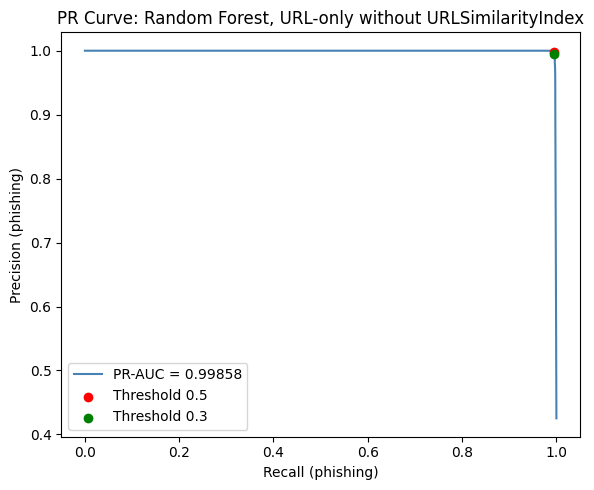

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# PR curve on test set (phishing = positive class)
prec, rec, _ = precision_recall_curve(y_test_phish, test_phish_score)
ap = average_precision_score(y_test_phish, test_phish_score)

plt.figure(figsize=(6, 5))
plt.plot(rec, prec, color='steelblue', label='PR-AUC = ' + str(round(ap, 5)))

# Mark the two thresholds we tested (values from our test output)
plt.scatter([0.99472], [0.99735], color='red', zorder=3, label='Threshold 0.5')
plt.scatter([0.99569], [0.99496], color='green', zorder=3, label='Threshold 0.3')

plt.xlabel('Recall (phishing)')
plt.ylabel('Precision (phishing)')
plt.title('PR Curve: Random Forest, URL-only without URLSimilarityIndex')
plt.legend()
plt.tight_layout()
plt.show()

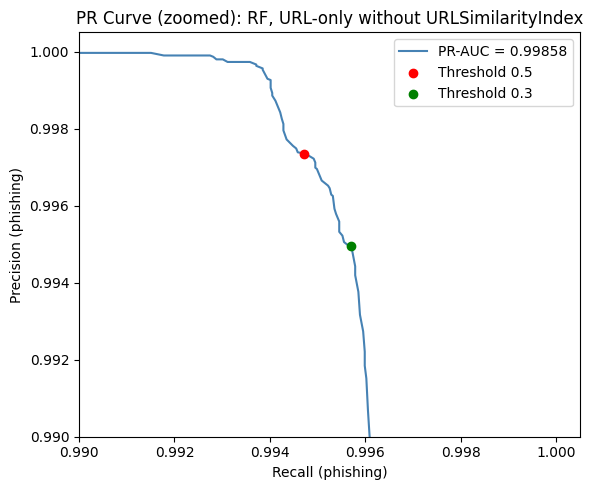

In [ ]:
# Zoomed PR curve: only the top-right corner
plt.figure(figsize=(6, 5))
plt.plot(rec, prec, color='steelblue', label='PR-AUC = ' + str(round(ap, 5)))
plt.scatter([0.99472], [0.99735], color='red', zorder=3, label='Threshold 0.5')
plt.scatter([0.99569], [0.99496], color='green', zorder=3, label='Threshold 0.3')

plt.xlim(0.99, 1.0005)
plt.ylim(0.99, 1.0005)
plt.xlabel('Recall (phishing)')
plt.ylabel('Precision (phishing)')
plt.title('PR Curve (zoomed): RF, URL-only without URLSimilarityIndex')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Save the threshold comparison (test set) so it is not lost
rows = []
for t in [0.5, 0.3]:
    pred = (test_phish_score >= t).astype(int)
    tp = ((pred == 1) & (y_test_phish == 1)).sum()
    fn = ((pred == 0) & (y_test_phish == 1)).sum()
    fp = ((pred == 1) & (y_test_phish == 0)).sum()
    rows.append({'Threshold': t, 'Recall': tp / (tp + fn),
                 'Precision': tp / (tp + fp), 'Missed': fn, 'False alarms': fp})
thr_table = pd.DataFrame(rows)
print(thr_table.to_string(index=False))
thr_table.to_csv('/content/threshold_results.csv', index=False)
print('Saved: threshold_results.csv')

 Threshold  Recall  Precision  Missed  False alarms
   0.50000 0.99472    0.99735     158            79
   0.30000 0.99569    0.99496     129           151
Saved: threshold_results.csv


In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Random Forest on all 50 features (best settings found earlier)
rf_imp = RandomForestClassifier(n_estimators=200, max_depth=None,
                                random_state=42, n_jobs=-1)
rf_imp.fit(X_train, y_train)

# Top 10 most used features
imp = pd.Series(rf_imp.feature_importances_, index=X_train.columns)
print(imp.sort_values(ascending=False).head(10).round(4))
print('Sum of all importances:', round(imp.sum(), 4))

URLSimilarityIndex   0.19730
NoOfExternalRef      0.16740
LineOfCode           0.13540
NoOfImage            0.11140
NoOfSelfRef          0.08540
NoOfJS               0.07520
HasSocialNet         0.03340
NoOfCSS              0.02990
HasDescription       0.02330
HasCopyrightInfo     0.02230
dtype: float64
Sum of all importances: 1.0


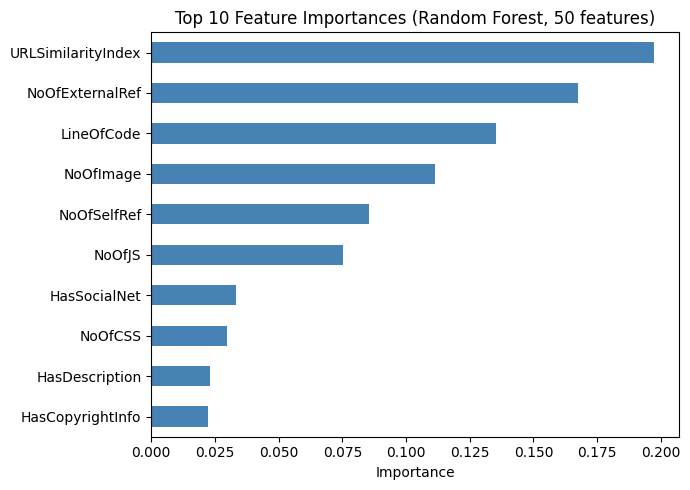

Saved: feature_importance.csv


In [ ]:
import matplotlib.pyplot as plt

# Horizontal bar chart of the top 10 features
top10_imp = imp.sort_values(ascending=False).head(10).sort_values()
top10_imp.plot(kind='barh', figsize=(7, 5), color='steelblue')
plt.title('Top 10 Feature Importances (Random Forest, 50 features)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

# Save the full importance table
imp.sort_values(ascending=False).round(5).to_csv('/content/feature_importance.csv')
print('Saved: feature_importance.csv')

DRAFT - rewrite in my own words before submission.

Why we doubted 99% scores: the course notes say a high score can be misleading if the data is imbalanced, if there is data leakage, or if the evaluation is wrong.

What we checked: the classes are close (57.49% and 42.51%). We removed duplicate rows. We fitted the scaler on training data only. We chose the threshold on training data only. A domain group split did not lower the scores.

What we could not prove: all results come from one split. We did not re-tune settings for the group split. We have not verified how URLSimilarityIndex is computed. So we cannot say leakage is impossible.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# 20 URL features: remove URLSimilarityIndex (already out) and TLDLegitimateProb
url_cols_clean = [c for c in url_cols_nosim if c != 'TLDLegitimateProb']
print('Features:', len(url_cols_clean))

dt_grid = {'max_depth': [3, 5, 10, None],
           'min_samples_leaf': [1, 5, 20]}

dt_clean_search = GridSearchCV(DecisionTreeClassifier(random_state=42),
                               dt_grid, scoring=f1_phish, cv=3, n_jobs=-1)
dt_clean_search.fit(X_train[url_cols_clean], y_train)

print('Best params:', dt_clean_search.best_params_)
print('Best CV F1 (phishing):', round(dt_clean_search.best_score_, 4))

dt_clean_result = evaluate(dt_clean_search.best_estimator_, X_test[url_cols_clean],
                           y_test, 'Decision Tree (URL-only, no SimIdx, no TLDProb)')
print(pd.Series(dt_clean_result))

Features: 20
Best params: {'max_depth': None, 'min_samples_leaf': 5}
Best CV F1 (phishing): 0.9951
Model        Decision Tree (URL-only, no SimIdx, no TLDProb)
Precision                                            0.99762
Recall                                               0.99335
F1                                                   0.99548
PR-AUC                                               0.99618
ROC-AUC                                              0.99690
Confusion                        [[29715, 199], [71, 40384]]
dtype: object


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest on the same 20 URL-only features
rf_clean_search = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                               {'n_estimators': [100, 200], 'max_depth': [10, None]},
                               scoring=f1_phish, cv=3, n_jobs=1)
rf_clean_search.fit(X_train[url_cols_clean], y_train)

print('Best params:', rf_clean_search.best_params_)
print('Best CV F1 (phishing):', round(rf_clean_search.best_score_, 4))

rf_clean_result = evaluate(rf_clean_search.best_estimator_, X_test[url_cols_clean],
                           y_test, 'Random Forest (URL-only, no SimIdx, no TLDProb)')
print(pd.Series(rf_clean_result))

# Save both 20-feature results
clean_table = pd.DataFrame([dt_clean_result, rf_clean_result])
clean_table['Phishing missed'] = clean_table['Confusion'].apply(lambda c: c[0][1])
clean_table['Legit flagged'] = clean_table['Confusion'].apply(lambda c: c[1][0])
cc = ['Model', 'Precision', 'Recall', 'F1', 'PR-AUC', 'ROC-AUC',
      'Phishing missed', 'Legit flagged']
clean_table[cc].to_csv('/content/url_clean_results.csv', index=False)
print('Saved: url_clean_results.csv')



Best params: {'max_depth': None, 'n_estimators': 100}
Best CV F1 (phishing): 0.9952
Model        Random Forest (URL-only, no SimIdx, no TLDProb)
Precision                                            0.99615
Recall                                               0.99485
F1                                                   0.99550
PR-AUC                                               0.99843
ROC-AUC                                              0.99859
Confusion                       [[29760, 154], [115, 40340]]
dtype: object
Saved: url_clean_results.csv


In [ ]:
import sys, pandas, numpy, sklearn, matplotlib
print('python', sys.version.split()[0])
print('pandas', pandas.__version__)
print('numpy', numpy.__version__)
print('scikit-learn', sklearn.__version__)
print('matplotlib', matplotlib.__version__)

python 3.13.16
pandas 2.2.3
numpy 2.4.6
scikit-learn 1.6.1
matplotlib 3.10.0
